# Gridworld control: policy iteration and value iteration

<a target="_blank" href="https://colab.research.google.com/github/changyaochen/MECE4520/blob/master/site/reinforcement-learning/03-gridworld-control.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

This notebook continues the zero-indexed Gridworld example. The environment is now a **Markov decision process (MDP)** because the agent can choose its policy. We will use a model of the environment to find a policy that maximizes expected discounted return.

Rows and columns run from 0 through 4. The special transitions are \(A=(0,1)\rightarrow A'=(4,1)\) with reward \(+10\), and \(B=(0,3)\rightarrow B'=(2,3)\) with reward \(+5\).

## What we will do

1. Recreate the Gridworld transition and reward rules.
2. Compute action values from the value function of a policy.
3. Alternate policy evaluation and greedy improvement with **policy iteration**.
4. Use **value iteration** to fold those two ideas into one Bellman-optimality update.

The preceding Gridworld notebook studies policy evaluation in detail. This notebook includes the same evaluator so that the control algorithms remain self-contained.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)

## 1. The zero-indexed Gridworld

At any state, the available actions are up, right, down, and left. An action that would leave the board keeps the agent in the same state and gives reward \(-1\). Every ordinary in-grid move has reward 0. At \(A\) and \(B\), every action triggers the listed teleport transition.

The functions below provide the **known model** needed by policy iteration and value iteration: given \((s,a)\), they return the deterministic next state \(s'\) and reward \(r\).

In [2]:
GRID_SIZE = 5
GAMMA = 0.9

# The action index is used as the final axis of a policy array.
ACTION_NAMES = np.array(['up', 'right', 'down', 'left'])
ACTION_ARROWS = np.array(['↑', '→', '↓', '←'])
ACTION_DELTAS = np.array([[-1, 0], [0, 1], [1, 0], [0, -1]])
N_ACTIONS = len(ACTION_NAMES)

# source: (destination, reward, source label, destination label)
TELEPORTS = {
    (0, 1): ((4, 1), 10.0, 'A', 'A′'),
    (0, 3): ((2, 3), 5.0, 'B', 'B′'),
}
TARGET_LABELS = {destination: target_label
                 for destination, _, _, target_label in TELEPORTS.values()}


def states():
    '''Yield all 25 states as zero-indexed (row, column) pairs.'''
    for row in range(GRID_SIZE):
        for column in range(GRID_SIZE):
            yield (row, column)


def in_grid(state):
    '''Return True when a zero-indexed state lies inside the board.'''
    row, column = state
    return 0 <= row < GRID_SIZE and 0 <= column < GRID_SIZE


def step(state, action_index):
    '''Return the deterministic (next_state, reward) for one action.'''
    if state in TELEPORTS:
        destination, reward, _, _ = TELEPORTS[state]
        return destination, reward

    candidate = tuple(np.asarray(state) + ACTION_DELTAS[action_index])
    if not in_grid(candidate):
        return state, -1.0
    return candidate, 0.0


for source, (destination, reward, source_label, target_label) in TELEPORTS.items():
    print(f'{source_label} at {source} → {target_label} at {destination}, reward {reward:+.0f}')

A at (0, 1) → A′ at (4, 1), reward +10
B at (0, 3) → B′ at (2, 3), reward +5


## 2. From state values to action values

For a fixed policy \(\pi\), the state value \(v_\pi(s)\) averages over actions. The **action value** keeps the first action explicit:

$$
q_\pi(s,a) = r(s,a,s') + \gamma v_\pi(s').
$$

The Gridworld is deterministic, so each \((s,a)\) has exactly one \(s'\) and one immediate reward. The code computes all four action values at a state, then policy evaluation averages them according to the current policy.

In [3]:
def uniform_random_policy():
    '''Return π(a|s)=1/4 for every state and every action.'''
    return np.full((GRID_SIZE, GRID_SIZE, N_ACTIONS), 1.0 / N_ACTIONS)


def action_values(values, state):
    '''Compute r + γV(s′) for each possible action at one state.'''
    q_values = np.empty(N_ACTIONS)
    for action_index in range(N_ACTIONS):
        next_state, reward = step(state, action_index)
        q_values[action_index] = reward + GAMMA * values[next_state]
    return q_values


def evaluate_policy(policy, tolerance=1e-9, max_sweeps=10_000):
    '''Evaluate a fixed policy by synchronous Bellman expectation backups.'''
    values = np.zeros((GRID_SIZE, GRID_SIZE))
    changes = []

    for _ in range(max_sweeps):
        # A fresh array makes this a synchronous sweep: every backup uses V_k.
        next_values = np.zeros_like(values)
        for state in states():
            row, column = state
            next_values[state] = policy[row, column] @ action_values(values, state)

        max_change = np.max(np.abs(next_values - values))
        changes.append(max_change)
        values = next_values
        if max_change < tolerance:
            break
    else:
        raise RuntimeError('Policy evaluation did not converge.')

    return values, np.asarray(changes)


random_policy = uniform_random_policy()
random_values, random_changes = evaluate_policy(random_policy)

example_state = (2, 2)
print(f'Random-policy evaluation converged in {len(random_changes)} sweeps.')
print(f'Action values at {example_state}:')
print(pd.Series(action_values(random_values, example_state), index=ACTION_NAMES).round(3))

Random-policy evaluation converged in 156 sweeps.
Action values at (2, 2):
up       2.025
right    0.322
down    -0.319
left     0.664
dtype: float64


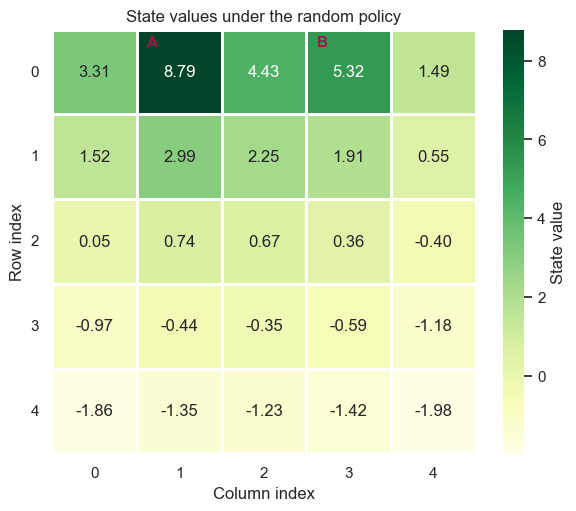

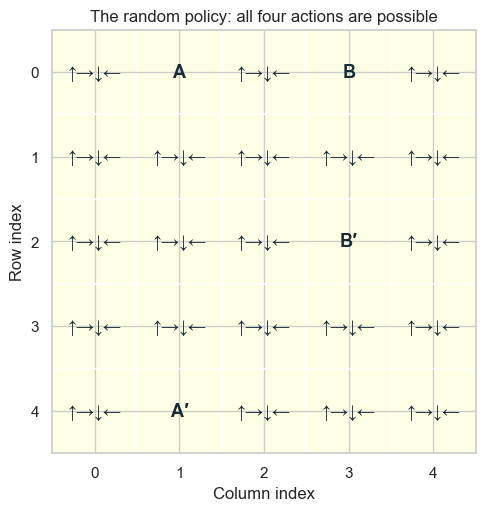

In [4]:
def plot_values(values, title):
    '''Show a state-value table with zero-indexed row and column ticks.'''
    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(values, annot=True, fmt='.2f', cmap='YlGn',
                square=True, linewidths=0.8, linecolor='white',
                cbar_kws={'label': 'State value'}, ax=ax)
    ax.set(title=title, xlabel='Column index', ylabel='Row index')
    ax.set_xticklabels(range(GRID_SIZE))
    ax.set_yticklabels(range(GRID_SIZE), rotation=0)
    for state, (_, _, source_label, _) in TELEPORTS.items():
        row, column = state
        ax.text(column + 0.12, row + 0.20, source_label,
                color='#9d174d', fontsize=11, fontweight='bold')
    plt.show()


def plot_policy(policy, title, values=None):
    '''Draw action choices; special states show their forced-transition label.'''
    fig, ax = plt.subplots(figsize=(7, 5.5))
    background = np.zeros((GRID_SIZE, GRID_SIZE)) if values is None else values
    image = ax.imshow(background, origin='upper', cmap='YlGn')
    if values is not None:
        fig.colorbar(image, ax=ax, label='State value')

    for state in states():
        row, column = state
        if state in TELEPORTS:
            label = TELEPORTS[state][2]
        elif state in TARGET_LABELS:
            label = TARGET_LABELS[state]
        else:
            chosen = np.flatnonzero(policy[row, column] > 1e-10)
            label = ''.join(ACTION_ARROWS[chosen])
        ax.text(column, row, label, ha='center', va='center',
                color='#172b35', fontsize=13, fontweight='bold')

    ax.set(title=title, xlabel='Column index', ylabel='Row index')
    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))
    ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=1.2)
    ax.tick_params(which='minor', bottom=False, left=False)
    plt.show()


plot_values(random_values, 'State values under the random policy')
plot_policy(random_policy, 'The random policy: all four actions are possible')

## 3. Greedy policy improvement

Once we have \(v_\pi\), we can choose the action with the largest \(q_\pi(s,a)\) at each state:

$$
\pi_{\mathrm{new}}(s) = \arg\max_a q_\pi(s,a).
$$

This step does not yet guarantee an optimal policy: it improves the policy relative to the values of the *current* policy. At \(A\) and \(B\), every action ties because the special transition ignores the chosen direction; the code retains all tied actions equally.

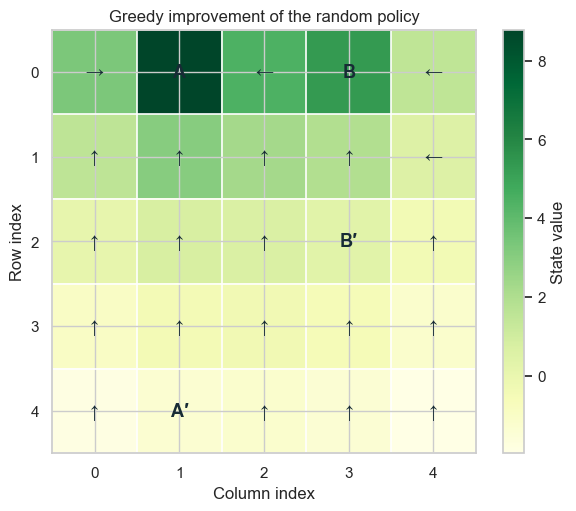

In [5]:
def greedy_policy(values):
    '''Return a policy that splits probability equally across tied best actions.'''
    policy = np.zeros((GRID_SIZE, GRID_SIZE, N_ACTIONS))
    for state in states():
        row, column = state
        q_values = action_values(values, state)
        best_actions = np.flatnonzero(np.isclose(q_values, q_values.max()))
        policy[row, column, best_actions] = 1.0 / len(best_actions)
    return policy


first_improved_policy = greedy_policy(random_values)
plot_policy(first_improved_policy, 'Greedy improvement of the random policy', random_values)

## 4. Policy iteration

**Policy iteration** alternates two complete operations:

1. **Policy evaluation:** calculate \(v_\pi\) for the current policy.
2. **Policy improvement:** replace that policy with \(\mathrm{greedy}(v_\pi)\).

When the greedy step leaves the policy unchanged, the policy is optimal. This works here because we know the transition and reward model exactly.

 policy update  evaluation sweeps  policy stable
             0                156          False
             1                220          False
             2                220          False
             3                220          False
             4                220           True


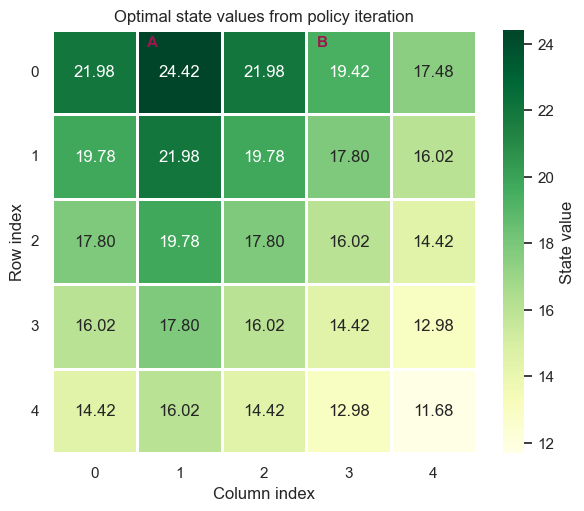

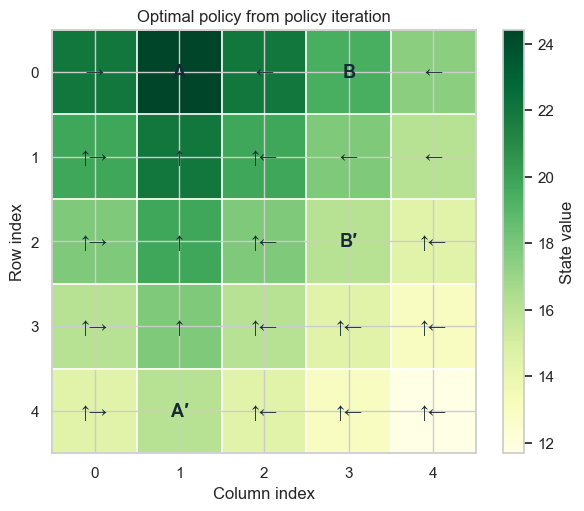

In [6]:
def policy_iteration(tolerance=1e-9, max_policy_updates=50):
    '''Alternate complete policy evaluation and greedy policy improvement.'''
    policy = uniform_random_policy()
    history = []

    for update in range(max_policy_updates):
        values, evaluation_changes = evaluate_policy(policy, tolerance=tolerance)
        improved_policy = greedy_policy(values)
        stable = np.allclose(improved_policy, policy)
        history.append({
            'policy update': update,
            'evaluation sweeps': len(evaluation_changes),
            'policy stable': stable,
        })
        if stable:
            return values, policy, pd.DataFrame(history)
        policy = improved_policy

    raise RuntimeError('Policy iteration did not stabilize.')


optimal_values_pi, optimal_policy_pi, policy_history = policy_iteration()
print(policy_history.to_string(index=False))
plot_values(optimal_values_pi, 'Optimal state values from policy iteration')
plot_policy(optimal_policy_pi, 'Optimal policy from policy iteration', optimal_values_pi)

## 5. Value iteration

Policy iteration evaluates one policy fully before improving it. **Value iteration** combines those steps by applying the Bellman optimality update directly:

$$
v_{k+1}(s) = \max_a \left[r(s,a,s') + \gamma v_k(s')\right].
$$

There is no explicit policy during the updates. After the values converge, we extract the policy by taking the greedy action at each state.

Value iteration converged in 220 sweeps.
Maximum difference from policy iteration: 0.00e+00


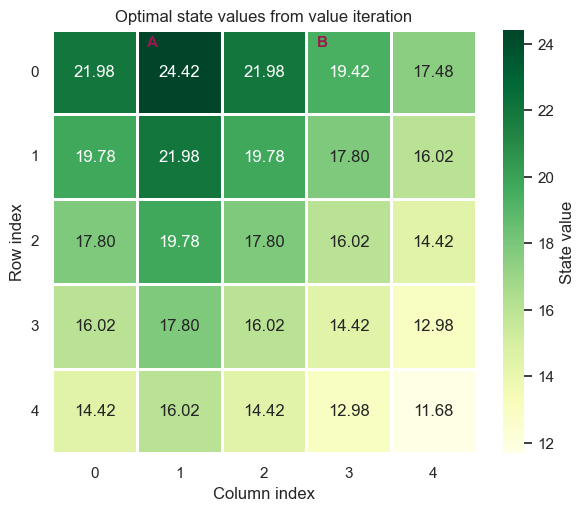

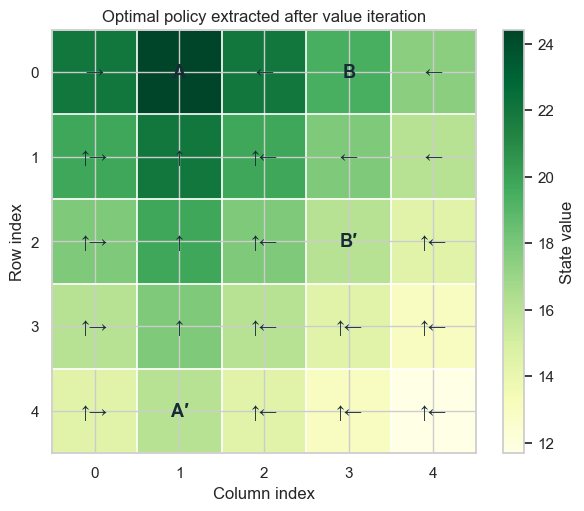

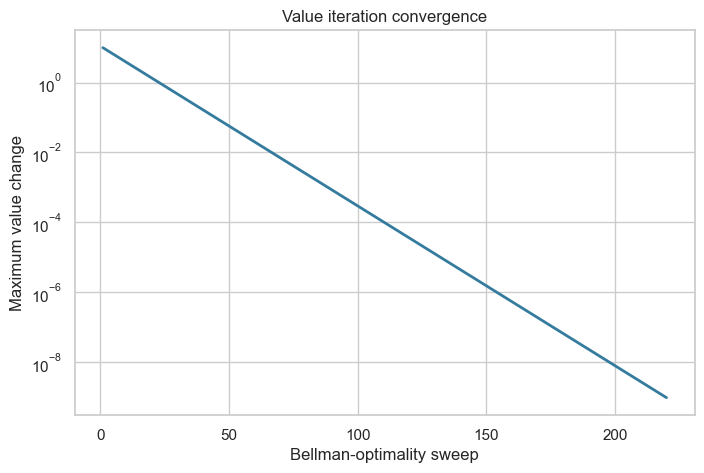

In [7]:
def value_iteration(tolerance=1e-9, max_sweeps=10_000):
    '''Apply synchronous Bellman optimality backups until the values converge.'''
    values = np.zeros((GRID_SIZE, GRID_SIZE))
    changes = []

    for _ in range(max_sweeps):
        next_values = np.zeros_like(values)
        for state in states():
            next_values[state] = action_values(values, state).max()

        max_change = np.max(np.abs(next_values - values))
        changes.append(max_change)
        values = next_values
        if max_change < tolerance:
            break
    else:
        raise RuntimeError('Value iteration did not converge.')

    return values, greedy_policy(values), np.asarray(changes)


optimal_values_vi, optimal_policy_vi, value_changes = value_iteration()
max_difference = np.max(np.abs(optimal_values_pi - optimal_values_vi))
print(f'Value iteration converged in {len(value_changes)} sweeps.')
print(f'Maximum difference from policy iteration: {max_difference:.2e}')

plot_values(optimal_values_vi, 'Optimal state values from value iteration')
plot_policy(optimal_policy_vi, 'Optimal policy extracted after value iteration', optimal_values_vi)

fig, ax = plt.subplots()
ax.semilogy(np.arange(1, len(value_changes) + 1), value_changes, color='#347b9e', linewidth=2)
ax.set(xlabel='Bellman-optimality sweep', ylabel='Maximum value change',
       title='Value iteration convergence')
plt.show()

## Takeaways

- A state value averages action values under a specified policy.
- Policy iteration alternates full evaluation with greedy improvement.
- Value iteration uses a maximum in every backup, then extracts a greedy policy after convergence.
- Both methods rely on the known Gridworld transition and reward model. Later, model-free methods must learn from sampled experience instead.

[← Return to Reinforcement learning](index.qmd)